# P20 – Sugar Check: Diabetes Predictor
**Name:** PRATIK SAVALIYA
**Roll No.:** D-47
**Enrollment No.:** 24004501210386 
**Division:** D

**Problem:** Predict diabetes from pregnancies, glucose, blood pressure, skin thickness, insulin, BMI, diabetes pedigree function and age.  
**Dataset:** https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database  
**Target (Y):** Outcome (0/1)  
**Model:** Logistic Regression  
**Main metrics:** Recall and F1

## Step 1: Create your notebook and load the libraries

In [21]:
# Step 1: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import piplite
await piplite.install("seaborn")
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
print("Libraries imported successfully.")

Libraries imported successfully.


## Step 2: Load your dataset

In [22]:
# Step 2: Load the dataset
# Upload diabetes.csv to your notebook folder first.
df = pd.read_csv("diabetes.csv")
print("Dataset shape (rows, columns):", df.shape)
display(df.head())

Dataset shape (rows, columns): (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## Step 3: Understand the data

In [23]:
# Step 3: Understand the data
display(df.head())
print("\nDataset information:")
df.info()
print("\nSummary statistics:")
display(df.describe().T)
print("\nMissing values in each column:")
display(df.isnull().sum().to_frame("Missing values"))
print("\nDuplicate rows:", df.duplicated().sum())

# Data dictionary for the Pima Indians Diabetes dataset
data_dictionary = pd.DataFrame({
    "Column name": ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
                    "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"],
    "Meaning": ["Number of pregnancies", "Blood glucose level", "Diastolic blood pressure",
                "Triceps skin-fold thickness", "Insulin level", "Body mass index",
                "Family-history diabetes score", "Age in years", "Diabetes (0=no, 1=yes)"],
    "Type": ["Number"] * 9,
    "Keep or drop": ["Keep"] * 9
})
display(data_dictionary)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00



Missing values in each column:


,Missing values
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0



Duplicate rows: 0


,Column name,Meaning,Type,Keep or drop
0,Pregnancies,Number of pregnancies,Number,Keep
1,Glucose,Blood glucose level,Number,Keep
2,BloodPressure,Diastolic blood pressure,Number,Keep
3,SkinThickness,Triceps skin-fold thickness,Number,Keep
4,Insulin,Insulin level,Number,Keep
5,BMI,Body mass index,Number,Keep
6,DiabetesPedigreeFunction,Family-history diabetes score,Number,Keep
7,Age,Age in years,Number,Keep
8,Outcome,"Diabetes (0=no, 1=yes)",Number,Keep


## Step 4: Prepare the target column (Y)

Target counts:


,Count
Outcome,
0,500
1,268



Target proportions:


,Proportion
Outcome,
0,0.651042
1,0.348958


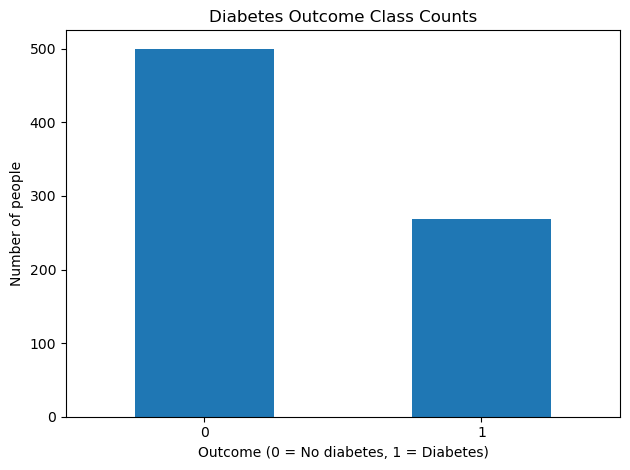

In [24]:
# Step 4: Check target classes
print("Target counts:")
display(df["Outcome"].value_counts().sort_index().to_frame("Count"))
print("\nTarget proportions:")
display(df["Outcome"].value_counts(normalize=True).sort_index().to_frame("Proportion"))
df["Outcome"].value_counts().sort_index().plot(kind="bar", rot=0)
plt.title("Diabetes Outcome Class Counts")
plt.xlabel("Outcome (0 = No diabetes, 1 = Diabetes)")
plt.ylabel("Number of people")
plt.tight_layout()
plt.show()

## Step 5: Clean the data

In [25]:
# Step 5: Clean the data
df = df.drop_duplicates().copy()

# In this dataset, zero values in these columns represent missing/invalid measurements.
zero_missing_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
for col in zero_missing_cols:
    df[col] = df[col].replace(0, np.nan)

# Fill numeric columns with their median.
for col in df.select_dtypes(include=np.number).columns:
    df[col] = df[col].fillna(df[col].median())

# If any text columns exist, fill them with the most common value.
for col in df.select_dtypes(exclude=np.number).columns:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].mode()[0])

print("Shape after removing duplicates:", df.shape)
print("Missing values after cleaning:", int(df.isnull().sum().sum()))
display(df.head())

Shape after removing duplicates: (768, 9)
Missing values after cleaning: 0


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


## Step 6: Explore the data with charts (EDA)

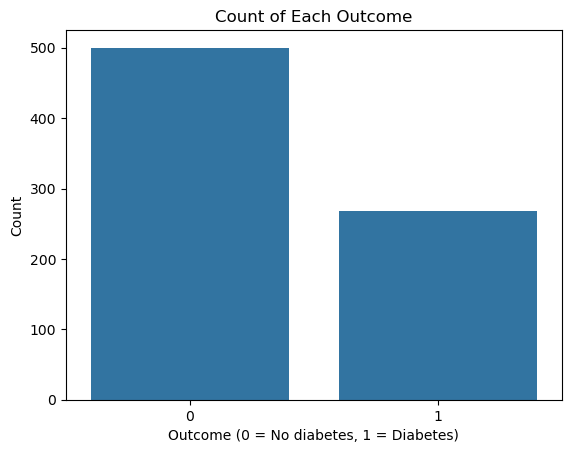

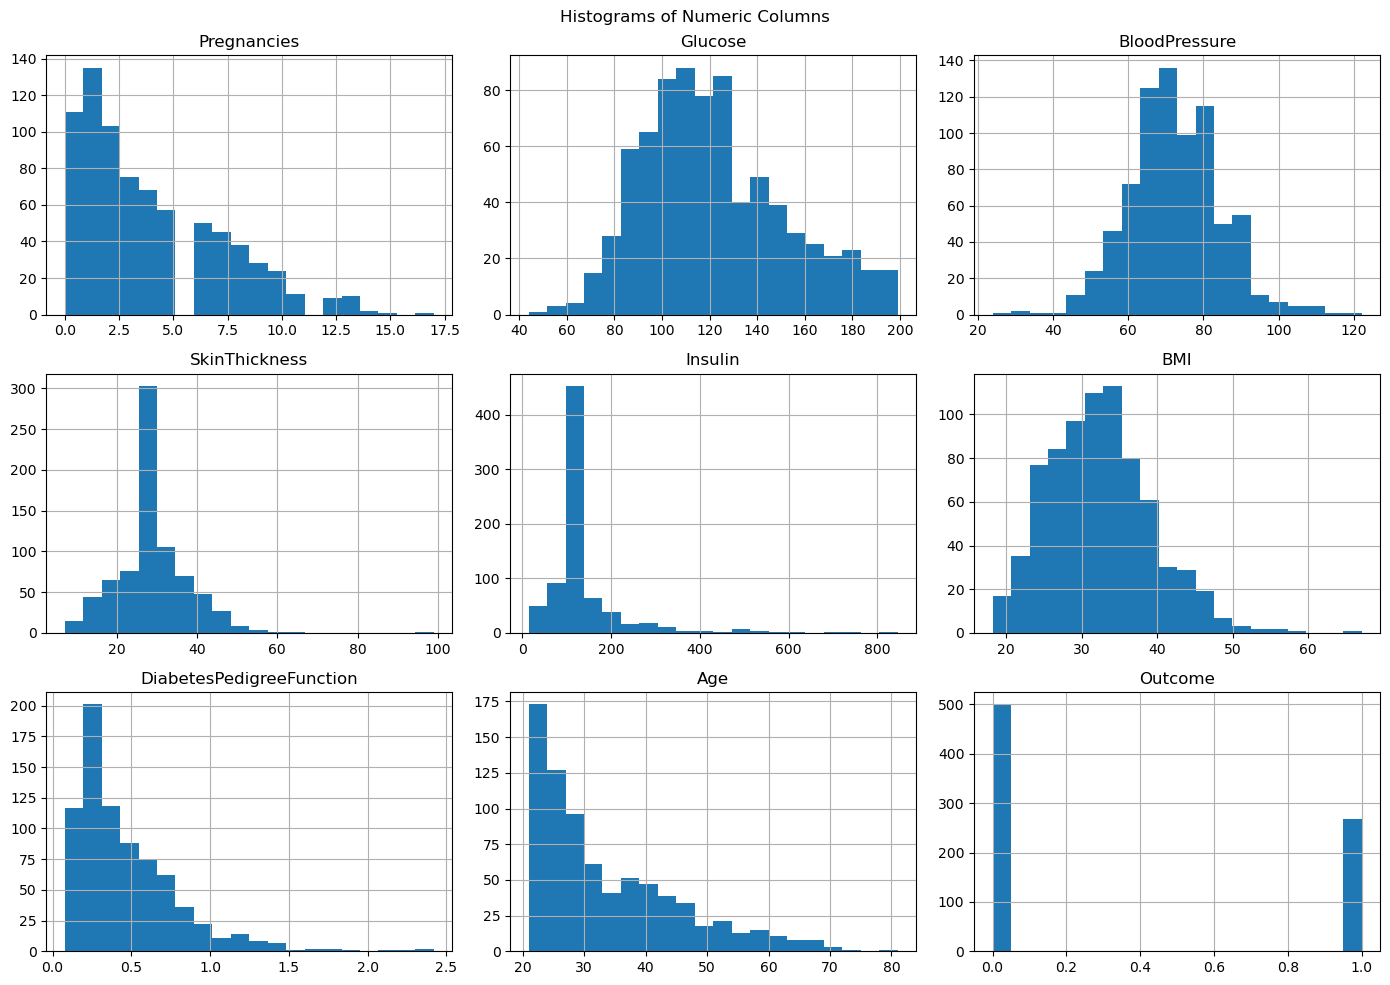

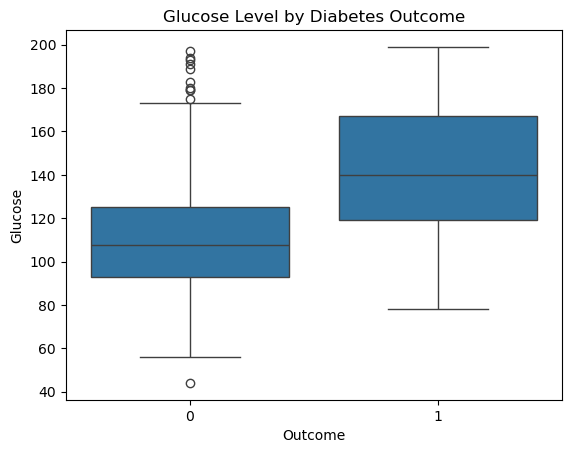

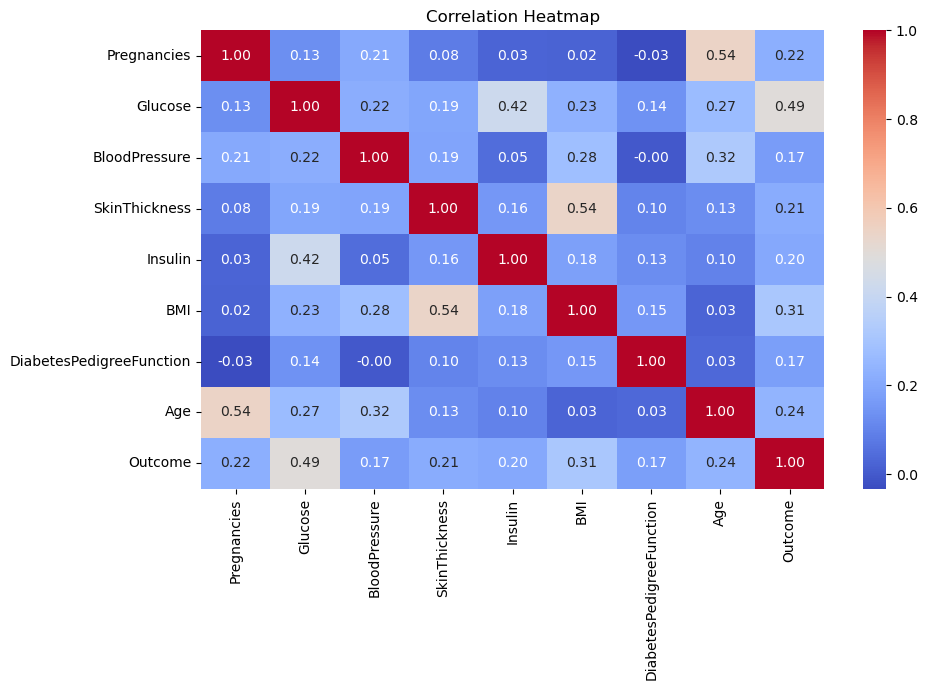

In [26]:
# Step 6: Explore data with charts (EDA)
sns.countplot(data=df, x="Outcome")
plt.title("Count of Each Outcome")
plt.xlabel("Outcome (0 = No diabetes, 1 = Diabetes)")
plt.ylabel("Count")
plt.show()

numeric_cols = df.select_dtypes(include=np.number).columns
df[numeric_cols].hist(figsize=(14, 10), bins=20)
plt.suptitle("Histograms of Numeric Columns")
plt.tight_layout()
plt.show()

sns.boxplot(data=df, x="Outcome", y="Glucose")
plt.title("Glucose Level by Diabetes Outcome")
plt.show()

plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## Step 7: Create a new feature, encode and select features

In [27]:
# Step 7: Feature engineering, encoding and feature selection
# BMI category is a simple feature derived from the BMI column.
df["BMI_Category"] = pd.cut(
    df["BMI"], bins=[-np.inf, 18.5, 25, 30, np.inf],
    labels=["Underweight", "Normal", "Overweight", "Obese"]
).astype(str)

X = df.drop(columns=["Outcome"])
y = df["Outcome"].astype(int)

# Encode target labels (0 and 1).
le_y = LabelEncoder()
y_encoded = le_y.fit_transform(y)

# Convert categorical feature(s) into numeric 0/1 columns.
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Select up to 15 useful features with ANOVA F-test.
k = min(15, X.shape[1])
selector = SelectKBest(score_func=f_classif, k=k)
X_selected_array = selector.fit_transform(X, y_encoded)
selected_features = X.columns[selector.get_support()].tolist()
X_selected = pd.DataFrame(X_selected_array, columns=selected_features, index=X.index)

print("New feature created: BMI_Category (groups BMI into four categories).")
print("Selected features:")
print(selected_features)
display(X_selected.head())

New feature created: BMI_Category (groups BMI into four categories).
Selected features:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'BMI_Category_Obese', 'BMI_Category_Overweight', 'BMI_Category_Underweight']


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,BMI_Category_Obese,BMI_Category_Overweight,BMI_Category_Underweight
0,6.0,148.0,72.0,35.0,125.0,33.6,0.627,50.0,1.0,0.0,0.0
1,1.0,85.0,66.0,29.0,125.0,26.6,0.351,31.0,0.0,1.0,0.0
2,8.0,183.0,64.0,29.0,125.0,23.3,0.672,32.0,0.0,0.0,0.0
3,1.0,89.0,66.0,23.0,94.0,28.1,0.167,21.0,0.0,1.0,0.0
4,0.0,137.0,40.0,35.0,168.0,43.1,2.288,33.0,1.0,0.0,0.0


## Step 8: Split into train and test + scale

In [28]:
# Step 8: Train-test split and scaling
X_train, X_test, y_train, y_test = train_test_split(
    X_selected, y_encoded, test_size=0.2, random_state=RANDOM_STATE, stratify=y_encoded
)

# Keep unscaled copies for comparison.
X_train_unscaled = X_train.copy()
X_test_unscaled = X_test.copy()

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)  # fit ONLY on training data
X_test_scaled = scaler.transform(X_test)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Training feature count:", X_train.shape[1])

Training rows: 614
Testing rows: 154
Training feature count: 11


## Step 9: Train your model: Logistic Regression

Baseline (default, scaled)
Confusion matrix [[TN, FP], [FN, TP]]:
[[81 19]
 [27 27]]

Classification report:
              precision    recall  f1-score   support

           0       0.75      0.81      0.78       100
           1       0.59      0.50      0.54        54

    accuracy                           0.70       154
   macro avg       0.67      0.66      0.66       154
weighted avg       0.69      0.70      0.70       154



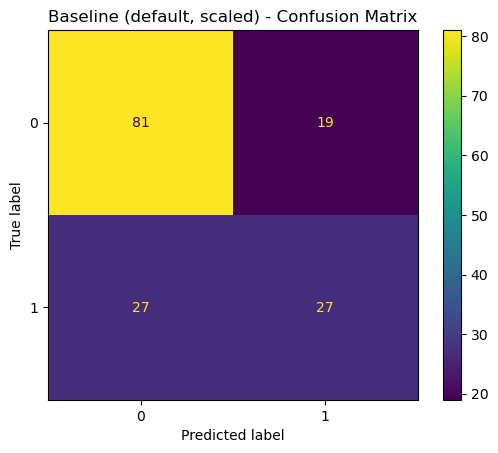

,Setting,Accuracy,Precision,Recall,F1,Specificity,AUC
0,"Baseline (default, scaled)",0.701,0.587,0.5,0.54,0.81,0.823


In [29]:
# Step 9: Baseline Logistic Regression and evaluation function
results = []

def evaluate(name, model, Xtr, Xte, scaled=False, show_details=False):
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    proba = model.predict_proba(Xte)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) else 0.0
    row = {
        "Setting": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "Specificity": specificity,
        "AUC": roc_auc_score(y_test, proba)
    }
    results.append(row)
    if show_details:
        print(name)
        print("Confusion matrix [[TN, FP], [FN, TP]]:")
        print(confusion_matrix(y_test, pred, labels=[0, 1]))
        print("\nClassification report:")
        print(classification_report(y_test, pred, zero_division=0))
        ConfusionMatrixDisplay.from_predictions(y_test, pred)
        plt.title(name + " - Confusion Matrix")
        plt.show()
    return row

baseline_model = LogisticRegression()
baseline_result = evaluate(
    "Baseline (default, scaled)", baseline_model,
    X_train_scaled, X_test_scaled, show_details=True
)
display(pd.DataFrame([baseline_result]).round(3))

## Step 10: Try different settings (tuning)

Intercept: -0.9238383533377728
Three strongest features:


,Feature,Coefficient,Absolute coefficient
1,Glucose,1.180454,1.180454
8,BMI_Category_Obese,0.507884,0.507884
5,BMI,0.484250,0.484250


,Threshold,Precision,Recall,F1
0,0.3,0.600,0.833,0.698
1,0.5,0.587,0.500,0.540
2,0.7,0.724,0.389,0.506


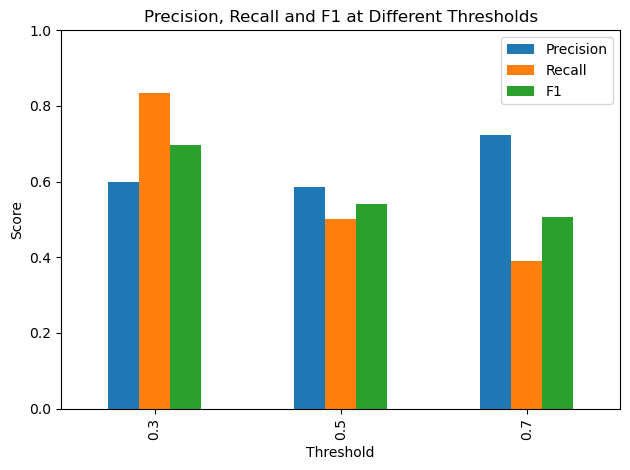

In [30]:

# Step 10: Tune settings and compare thresholds

tuning_models = {}

for scale_name, Xtr, Xte in [
    ("scaled", X_train_scaled, X_test_scaled),
    ("unscaled", X_train_unscaled, X_test_unscaled)
]:
    for weight in [None, "balanced"]:
        name = f"{scale_name}, class_weight={weight}"

        model = LogisticRegression(
            max_iter=5000,
            solver="lbfgs",
            class_weight=weight
        )

        evaluate(name, model, Xtr, Xte)
        tuning_models[name] = (model, Xtr, Xte)

# Fit Logistic Regression on scaled data
coef_model = LogisticRegression(
    max_iter=5000,
    solver="lbfgs"
)
coef_model.fit(X_train_scaled, y_train)

# Display the strongest features
coef_table = pd.DataFrame({
    "Feature": X_selected.columns,
    "Coefficient": coef_model.coef_[0]
})

coef_table["Absolute coefficient"] = coef_table["Coefficient"].abs()
coef_table = coef_table.sort_values(
    "Absolute coefficient", ascending=False
)

print("Intercept:", coef_model.intercept_[0])
print("Three strongest features:")
display(coef_table.head(3))

# Compare prediction thresholds
threshold_rows = []
probabilities = coef_model.predict_proba(X_test_scaled)[:, 1]

for threshold in [0.3, 0.5, 0.7]:
    pred_threshold = (probabilities >= threshold).astype(int)

    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test, pred_threshold, zero_division=0
        ),
        "F1": f1_score(
            y_test, pred_threshold, zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_rows)
display(threshold_df.round(3))

threshold_df.set_index("Threshold")[
    ["Precision", "Recall", "F1"]
].plot(kind="bar")

plt.title("Precision, Recall and F1 at Different Thresholds")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


## Step 11: Compare all settings and pick your final model

,Setting,Accuracy,Precision,Recall,F1,Specificity,AUC
0,"scaled, class_weight=balanced",0.753,0.618,0.778,0.689,0.74,0.823
1,"unscaled, class_weight=balanced",0.747,0.612,0.759,0.678,0.74,0.820
2,"Baseline (default, scaled)",0.701,0.587,0.500,0.540,0.81,0.823
3,"scaled, class_weight=None",0.701,0.587,0.500,0.540,0.81,0.823
4,"unscaled, class_weight=None",0.701,0.587,0.500,0.540,0.81,0.820


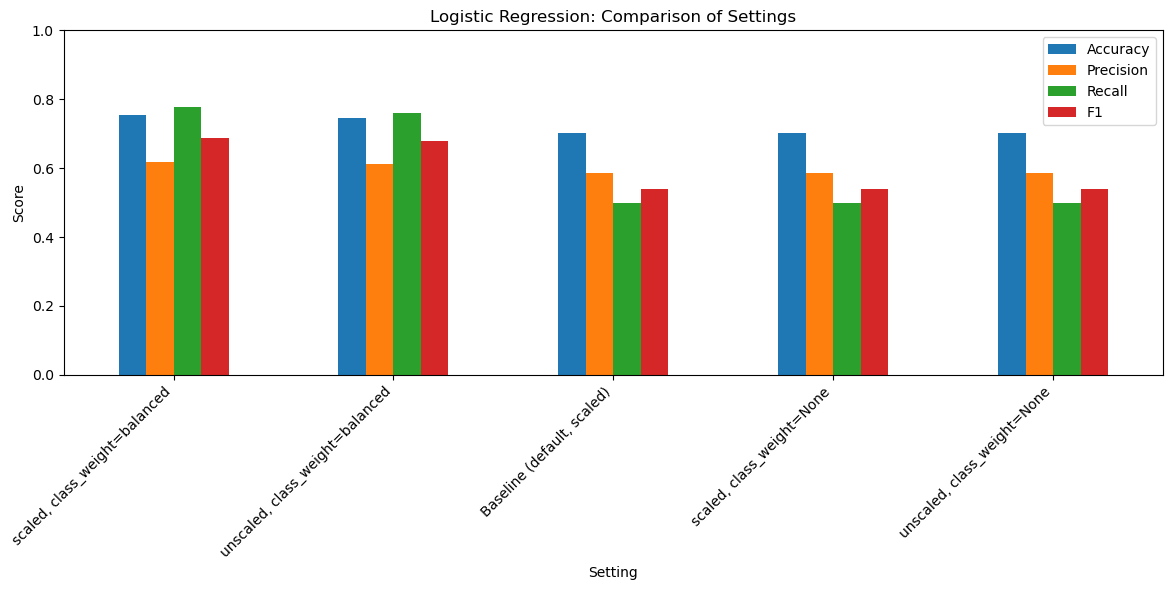

Best setting by Recall, then F1: scaled, class_weight=balanced

Final model classification report:
              precision    recall  f1-score   support

           0       0.86      0.74      0.80       100
           1       0.62      0.78      0.69        54

    accuracy                           0.75       154
   macro avg       0.74      0.76      0.74       154
weighted avg       0.78      0.75      0.76       154



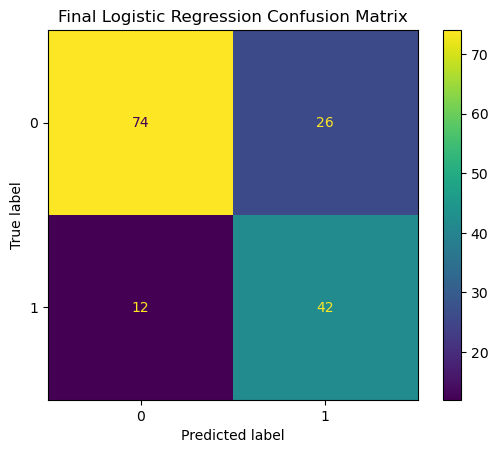

Final metrics:


,Setting,Accuracy,Precision,Recall,F1,Specificity,AUC
0,"scaled, class_weight=balanced",0.753,0.618,0.778,0.689,0.74,0.823


In [33]:
# Step 11: Compare all settings and choose final model
results_df = pd.DataFrame(results).drop_duplicates(subset=["Setting"], keep="last")
results_df = results_df.sort_values(["Recall", "F1"], ascending=False).reset_index(drop=True)
display(results_df.round(3))

# Compare main metrics for every setting.
results_df.set_index("Setting")[["Accuracy", "Precision", "Recall", "F1"]].plot(
    kind="bar", figsize=(12, 6)
)
plt.title("Logistic Regression: Comparison of Settings")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Select best setting by Recall, then F1 as the tie-breaker.
best_setting = results_df.iloc[0]["Setting"]
print("Best setting by Recall, then F1:", best_setting)

if best_setting.startswith("scaled"):
    final_X_train, final_X_test = X_train_scaled, X_test_scaled
else:
    final_X_train, final_X_test = X_train_unscaled, X_test_unscaled

best_weight = "balanced" if "class_weight=balanced" in best_setting else None
#final_model = LogisticRegression(max_iter=1000, class_weight=best_weight)
final_model = LogisticRegression(
    max_iter=5000,
    solver="lbfgs",
    class_weight=best_weight
)
final_model.fit(final_X_train, y_train)
final_predictions = final_model.predict(final_X_test)

print("\nFinal model classification report:")
print(classification_report(y_test, final_predictions, zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, final_predictions)
plt.title("Final Logistic Regression Confusion Matrix")
plt.show()
print("Final metrics:")
display(results_df[results_df["Setting"] == best_setting].round(3))

## Step 12: Predict 3 new inputs

In [34]:
# Step 12: Predict 3 new examples
# Start with three real rows, then make small realistic changes.
new_inputs = X_test_unscaled.iloc[:3].copy()
new_inputs = new_inputs.reset_index(drop=True)

# Keep the same feature columns and apply the same scaler only if final model used scaling.
if best_setting.startswith("scaled"):
    new_inputs_for_model = scaler.transform(new_inputs)
else:
    new_inputs_for_model = new_inputs

new_predictions = final_model.predict(new_inputs_for_model)
new_probabilities = final_model.predict_proba(new_inputs_for_model)[:, 1]

prediction_table = new_inputs.copy()
prediction_table["Predicted Outcome"] = le_y.inverse_transform(new_predictions)
prediction_table["Predicted diabetes probability"] = new_probabilities.round(3)
display(prediction_table)
print("Note: These are example predictions for learning, not a medical diagnosis.")

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,BMI_Category_Obese,BMI_Category_Overweight,BMI_Category_Underweight,Predicted Outcome,Predicted diabetes probability
0,7.0,159.0,64.0,29.0,125.0,27.4,0.294,40.0,0.0,1.0,0.0,1,0.749
1,10.0,68.0,106.0,23.0,49.0,35.5,0.285,47.0,1.0,0.0,0.0,0,0.228
2,2.0,122.0,76.0,27.0,200.0,35.9,0.483,26.0,1.0,0.0,0.0,0,0.450


Note: These are example predictions for learning, not a medical diagnosis.
